
# Loan Default Risk Analysis — Statistical Testing

## 1. Project Overview

This notebook applies statistical techniques to investigate patterns in loan defaults using the full loan dataset of 27,003 records.

The analysis uses hypothesis testing to examine whether observed default rates differ across selected borrower groups.

### Objectives
- Compare default rates between interest-rate groups.
- Test the association between credit grade and loan default status.
- Interpret p-values and confidence intervals.
- Translate statistical results into business insights.


In [2]:
%pip install scipy statsmodels

  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)
     ---------------------------------------- 11.4/11.4 MB 3.8 MB/s eta 0:00:00
     -------------------------------------- 233.3/233.3 kB 3.5 MB/s eta 0:00:00
     -------------------------------------- 118.9/118.9 kB 3.5 MB/s eta 0:00:00
     -------------------------------------- 483.2/483.2 kB 3.4 MB/s eta 0:00:00
     -------------------------------------- 105.4/105.4 kB 3.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

print("Libraries imported successfully.")


Libraries imported successfully.



## 2. Load the Dataset

Load the original loan dataset and verify its dimensions before conducting statistical tests.


In [5]:

df = pd.read_csv("../Data/loan_train.csv")

# Convert interest rate from text (e.g., "7.29%") to numeric
df["interest_rate"] = pd.to_numeric(
    df["int_rate"].astype("string")
      .str.replace("%", "", regex=False)
      .str.strip(),
    errors="coerce"
)

print("Dataset shape:", df.shape)
print("Missing interest rates:", df["interest_rate"].isna().sum())

display(df[["loan_status", "int_rate", "interest_rate"]].head())

Dataset shape: (27003, 48)
Missing interest rates: 0


,loan_status,int_rate,interest_rate
0,0,13.23%,13.23
1,0,7.88%,7.88
2,0,8.94%,8.94
3,0,7.29%,7.29
4,1,6.62%,6.62


## 3. Hypothesis Test — Interest Rate and Loan Defaults

A two-proportion z-test will determine whether the default rates of loans with interest rates below 12% and those with interest rates of 12% or higher are statistically different.

We use a significance level of 5% (α = 0.05).

In [6]:
# Remove records with missing interest rates
test_df = df.dropna(subset=["interest_rate"]).copy()

# Split loans into two groups
low_rate = test_df[test_df["interest_rate"] < 12]
high_rate = test_df[test_df["interest_rate"] >= 12]

# Count defaults and total loans in each group
defaults = [
    (low_rate["loan_status"] == 1).sum(),
    (high_rate["loan_status"] == 1).sum()
]

totals = [len(low_rate), len(high_rate)]

# Calculate default rates
low_default_rate = defaults[0] / totals[0]
high_default_rate = defaults[1] / totals[1]

# Perform two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=defaults,
    nobs=totals,
    alternative="two-sided"
)

print(f"Loans below 12%: {totals[0]:,}")
print(f"Default rate below 12%: {low_default_rate:.2%}")
print(f"Loans at or above 12%: {totals[1]:,}")
print(f"Default rate at or above 12%: {high_default_rate:.2%}")
print(f"Difference (high - low): {(high_default_rate - low_default_rate) * 100:.2f} percentage points")
print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Conclusion: Reject H0. The default rates are statistically different.")
else:
    print("Conclusion: Fail to reject H0. There is insufficient evidence of a difference.")

Loans below 12%: 14,514
Default rate below 12%: 9.16%
Loans at or above 12%: 12,489
Default rate at or above 12%: 21.19%
Difference (high - low): 12.03 percentage points
Z-statistic: -27.8151
P-value: 0.000000
Conclusion: Reject H0. The default rates are statistically different.


### Interpretation

The two-proportion z-test found a statistically significant difference in default rates between the two interest-rate groups (p < 0.05).

Loans with interest rates below 12% had a default rate of 9.16%, compared with 21.19% for loans with interest rates of 12% or higher. This represents a difference of 12.03 percentage points.

These findings suggest that higher interest rates are associated with greater default risk in this dataset. However, the result does not establish causation, as other borrower and loan characteristics may influence default risk.

## 4. Hypothesis Test — Credit Grade and Loan Defaults

A Chi-square test of independence will help determine whether credit grade is associated with loan default status.

- **Null hypothesis (H₀):** Credit grade and loan default status are independent.
- **Alternative hypothesis (H₁):** Credit grade and loan default status are associated.
- **Significance level:** 0.05.

In [7]:
# Create a contingency table
grade_table = pd.crosstab(df["grade"], df["loan_status"])

display(grade_table)

# Perform Chi-square test
chi2_stat, p_value, dof, expected = chi2_contingency(grade_table)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.10g}")

if p_value < 0.05:
    print("Conclusion: Reject H0. Credit grade is associated with loan default status.")
else:
    print("Conclusion: Fail to reject H0. There is insufficient evidence of an association.")

loan_status,0,1
grade,,
A,6623,431
B,7194,995
C,4497,956
D,2743,789
E,1347,511
F,478,220
G,144,75


Chi-square statistic: 1122.0573
Degrees of freedom: 6
P-value: 3.522341297e-239
Conclusion: Reject H0. Credit grade is associated with loan default status.


### Interpretation

The Chi-square test of independence found a statistically significant association between credit grade and loan default status (χ² = 1122.06, df = 6, p < 0.05).

The results indicate that default outcomes are not independent of credit grade in this dataset. Therefore, credit grade may be a useful factor to consider when assessing loan default risk.

This test identifies an association but does not establish causation.

## 5. Confidence Interval for the Overall Default Rate

A 95% confidence interval provides a range of plausible values for the population default rate based on the observed sample.

In [8]:
default_count = (df["loan_status"] == 1).sum()
total_loans = df["loan_status"].notna().sum()

ci_low, ci_high = proportion_confint(
    count=default_count,
    nobs=total_loans,
    alpha=0.05,
    method="wilson"
)

observed_rate = default_count / total_loans

print(f"Total loans: {total_loans:,}")
print(f"Defaulted loans: {default_count:,}")
print(f"Observed default rate: {observed_rate:.2%}")
print(f"95% confidence interval: {ci_low:.2%} to {ci_high:.2%}")

Total loans: 27,003
Defaulted loans: 3,977
Observed default rate: 14.73%
95% confidence interval: 14.31% to 15.16%


### Interpretation

The observed default rate across 27,003 loans was 14.73%. The 95% Wilson confidence interval ranged from 14.31% to 15.16%.

This interval quantifies the statistical uncertainty around the observed default rate. It provides a useful baseline for monitoring portfolio-level default risk, subject to the representativeness of the dataset.

## 6. Default Rates by Credit Grade with Confidence Intervals

This analysis calculates the default rate for each credit grade and its 95% Wilson confidence interval. It helps compare default risk across grades while considering uncertainty in the estimates.

In [9]:
# Calculate default rates and confidence intervals by grade
grade_results = []

for grade, group in df.groupby("grade"):
    group = group.dropna(subset=["loan_status"])

    total = len(group)
    defaults = (group["loan_status"] == 1).sum()
    rate = defaults / total

    ci_low, ci_high = proportion_confint(
        count=defaults,
        nobs=total,
        alpha=0.05,
        method="wilson"
    )

    grade_results.append({
        "Credit Grade": grade,
        "Total Loans": total,
        "Defaults": defaults,
        "Default Rate (%)": round(rate * 100, 2),
        "95% CI Lower (%)": round(ci_low * 100, 2),
        "95% CI Upper (%)": round(ci_high * 100, 2)
    })

grade_results_df = pd.DataFrame(grade_results)
display(grade_results_df)

,Credit Grade,Total Loans,Defaults,Default Rate (%),95% CI Lower (%),95% CI Upper (%)
0,A,7054,431,6.11,5.57,6.69
1,B,8189,995,12.15,11.46,12.88
2,C,5453,956,17.53,16.55,18.56
3,D,3532,789,22.34,21.00,23.74
4,E,1858,511,27.50,25.52,29.58
5,F,698,220,31.52,28.18,35.06
6,G,219,75,34.25,28.28,40.75


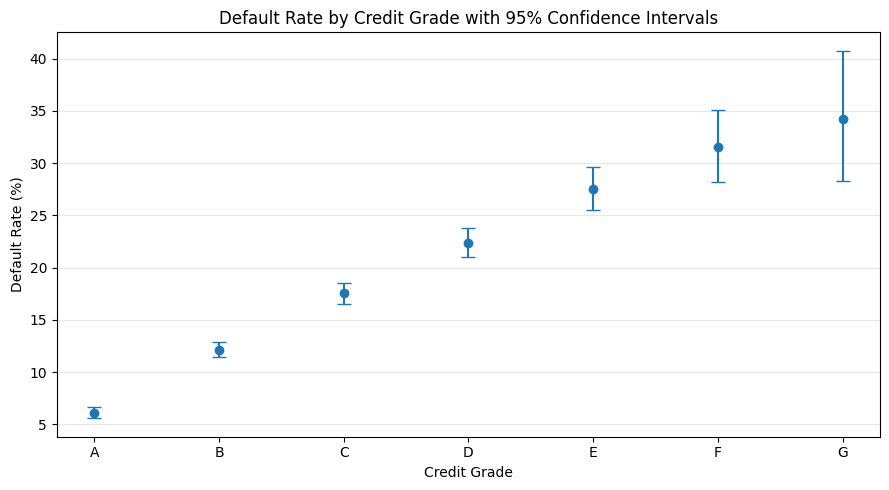

In [10]:
import matplotlib.pyplot as plt

results = grade_results_df.sort_values("Credit Grade")

rates = results["Default Rate (%)"]
lower_errors = rates - results["95% CI Lower (%)"]
upper_errors = results["95% CI Upper (%)"] - rates

plt.figure(figsize=(9, 5))
plt.errorbar(
    results["Credit Grade"],
    rates,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=5
)

plt.title("Default Rate by Credit Grade with 95% Confidence Intervals")
plt.xlabel("Credit Grade")
plt.ylabel("Default Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

Default rates increased consistently from Grade A (6.11%) to Grade G (34.25%), indicating a strong relationship between credit grade and observed loan default risk.

Grades E, F and G showed higher default rates, while Grade A had the lowest rate. The confidence intervals were wider for grades with fewer loans, particularly Grade G, reflecting greater uncertainty in those estimates.

From a business perspective, lenders could use credit grades as one component of risk-based loan assessment and monitoring. However, credit grade should not be used as the sole basis for lending decisions.